In [1]:
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

# Optional
plt.style.use('seaborn-v0_8-darkgrid')

In [2]:
data_dir = 'processed/session_4_7'

# 1. Load Time-Series (Signals)
X = np.load(f'{data_dir}/X_features.npy')
U = np.load(f'{data_dir}/U_exogenous.npy')
conditions = pd.read_csv(f'{data_dir}/conditions.csv')

# 2. Load Graph (Topology)
edge_index = torch.load(f'{data_dir}/edge_index.pt')
edge_weight = torch.load(f'{data_dir}/edge_weight.pt')

print(f"Features (X): {X.shape} -> [Timesteps, Neurons]")
print(f"Exogenous (U): {U.shape} -> [Timesteps, Covariates]")
print(f"Edge Index: {edge_index.shape} -> [2, Num_Edges]")

Features (X): (37840, 1059) -> [Timesteps, Neurons]
Exogenous (U): (37840, 5) -> [Timesteps, Covariates]
Edge Index: torch.Size([2, 27229]) -> [2, Num_Edges]


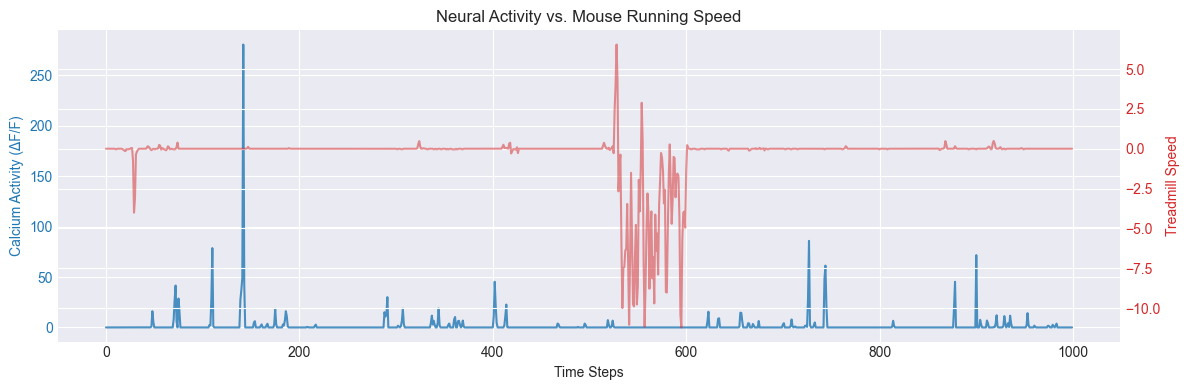

In [3]:
# Plot the first 1000 timesteps for a single neuron and the treadmill speed
timesteps = 1000
target_neuron = 0

fig, ax1 = plt.subplots(figsize=(12, 4))

# Calcium trace (Primary Y-axis)
color = 'tab:blue'
ax1.set_xlabel('Time Steps')
ax1.set_ylabel('Calcium Activity (ΔF/F)', color=color)
ax1.plot(X[:timesteps, target_neuron], color=color, alpha=0.8, label='Neuron 0')
ax1.tick_params(axis='y', labelcolor=color)

# Treadmill speed (Secondary Y-axis)
ax2 = ax1.twinx()  
color = 'tab:red'
ax2.set_ylabel('Treadmill Speed', color=color)
ax2.plot(U[:timesteps, 0], color=color, alpha=0.5, label='Running Speed')
ax2.tick_params(axis='y', labelcolor=color)

plt.title("Neural Activity vs. Mouse Running Speed")
fig.tight_layout()
plt.show()

Dense Adjacency Matrix Shape: torch.Size([1059, 1059])


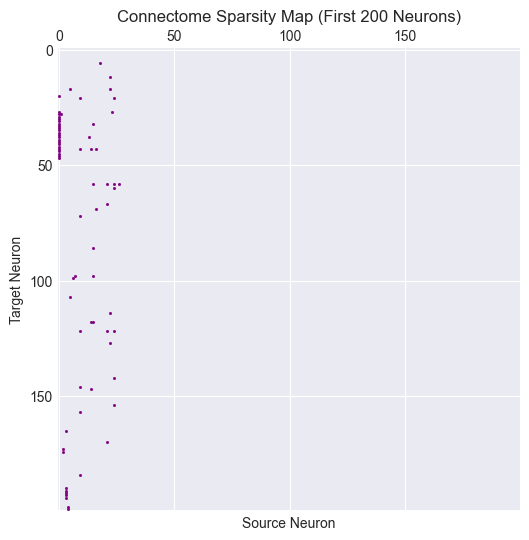

In [4]:
# Convert PyG Edge Index to a Dense Adjacency Matrix
num_nodes = X.shape[1]
A = torch.zeros((num_nodes, num_nodes), dtype=torch.float32)

# Information flows from src (row 0) to dst (row 1)
src = edge_index[0, :]
dst = edge_index[1, :]
A[dst, src] = edge_weight

print(f"Dense Adjacency Matrix Shape: {A.shape}")

# Plot a sparsity map (spy plot) of the first 200x200 neurons
plt.figure(figsize=(6, 6))
plt.spy(A[:200, :200].numpy(), markersize=1, color='purple')
plt.title("Connectome Sparsity Map (First 200 Neurons)")
plt.xlabel("Source Neuron")
plt.ylabel("Target Neuron")
plt.show()

=== Synapse Count Statistics ===
Total Edges: 27229
Mean Synapses per Edge: 0.01
Median Synapses: 0.00
Max Synapses on a single edge: 4
Min Synapses on a single edge: 0


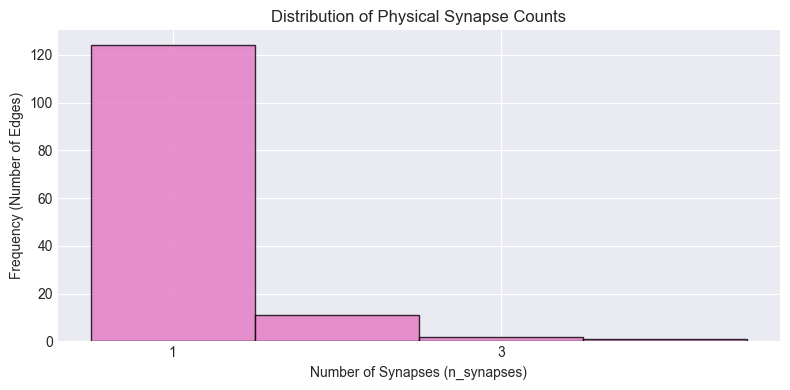

In [5]:
# Analyze Synapse Counts (Edge Weights)
weights = edge_weight.numpy()

print("=== Synapse Count Statistics ===")
print(f"Total Edges: {len(weights)}")
print(f"Mean Synapses per Edge: {weights.mean():.2f}")
print(f"Median Synapses: {np.median(weights):.2f}")
print(f"Max Synapses on a single edge: {weights.max():.0f}")
print(f"Min Synapses on a single edge: {weights.min():.0f}")

# Plot the distribution
fig, ax = plt.subplots(figsize=(8, 4))
bins = range(1, int(weights.max()) + 2)
ax.hist(weights, bins=bins, color='tab:pink', edgecolor='black', alpha=0.8, align='left')

ax.set_title("Distribution of Physical Synapse Counts")
ax.set_xlabel("Number of Synapses (n_synapses)")
ax.set_ylabel("Frequency (Number of Edges)")
ax.set_xticks(range(1, int(weights.max()) + 1, 2)) # Tick every 2 synapses

plt.tight_layout()
plt.show()